# Raport Laboratori

**Lënda:** Hyrje në Elektronikë  
**Tema:** Matjet me Oshiloskop dhe Qarqet RC

**Emri:** Alda Xhika  
**Data e punimit:** 22/11/2026  
**Data e dorëzimit:** 22/11/2026

## 1. Qëllimi i Eksperimentit

Qëllimi i këtij eksperimenti është kryerja e matjeve me oshiloskop dhe analizimi i vlerave të periodës ($T$) dhe frekuencës ($f$) për katër konfigurime/kondensatorë të shënuar si `1`, `2`, `3` dhe `4`.

## 2. Baza Teorike

* **Lidhja midis periodës dhe frekuencës:** Frekuenca ($f$) është e anasjellta e periodës ($T$):
  $$f = \frac{1}{T} \quad \text{dhe} \quad T = \frac{1}{f}$$

* **Njësitë e matjes:** Perioda në tabelë jepet në sekonda ($10^{-6}\text{ s} = \mu\text{s}$), ndërsa frekuenca jepet në kilohertz ($\text{kHz} = 10^3\text{ Hz}$) dhe megahertz ($\text{MHz} = 10^6\text{ Hz}$).

## 3. Ndërtimi Eksperimental

1. Përgatitja e qarkut në *breadboard* dhe lidhja e sondave të oshiloskopit në pikat e matjes.
2. Regjistrimi i vlerave të periodës $T\text{ (s)}$ dhe frekuencës $f\text{ (Hz)}$ për rastet `1`, `2`, `3` dhe `4`.
3. Ruajtja e të dhënave në skedarin `tabela_e_eksperimenteve.csv` dhe analiza e tyre në Python.

# 4. Te Dhenat e Matura

In [10]:
import numpy as np
import pandas as pd

data = {
    "Kondesator (C)": [1, 2, 3, 4],
    "T (s)": [3e-6, 6e-6, 2e-6, 1e-6],
    "f (Hz)": ["110.7 kHz", "333.3 kHz", "300 kHz", "1 MHz"],
}

df = pd.DataFrame(data)
display(df)

,Kondesator (C),T (s),f (Hz)
0,1,0.000003,110.7 kHz
1,2,0.000006,333.3 kHz
2,3,0.000002,300 kHz
3,4,0.000001,1 MHz


# 5. Analiza e Te Dhenave

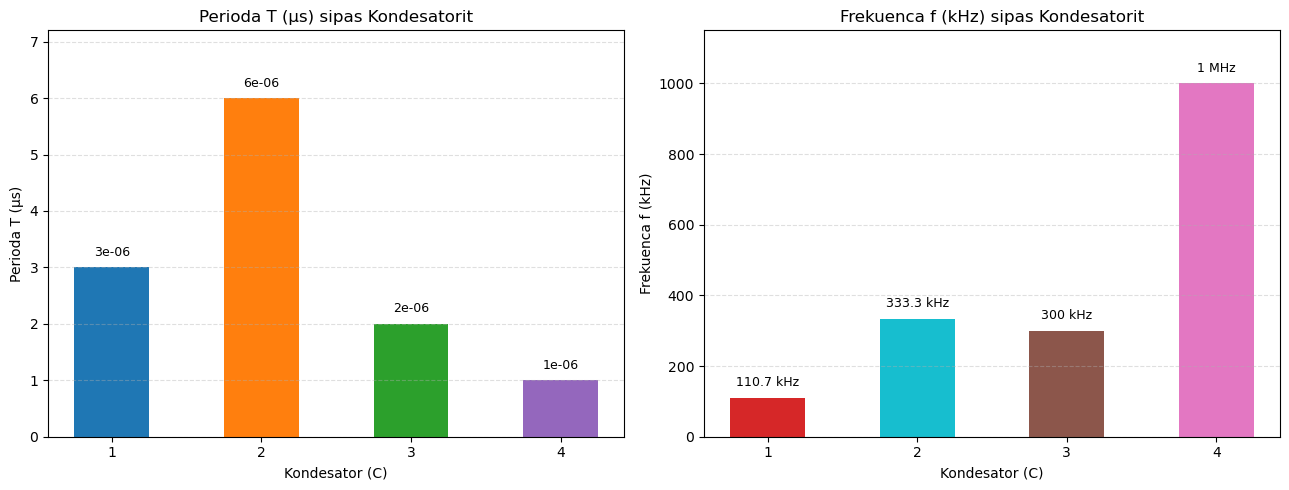

In [11]:
import matplotlib.pyplot as plt

kond = df["Kondesator (C)"].astype(str)
t_us = df["T (s)"] * 1e6
f_khz = [110.7, 333.3, 300.0, 1000.0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafiku 1: Perioda T (µs)
bars_t = axes[0].bar(
    kond, t_us, width=0.5, color=["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]
)
axes[0].set_title("Perioda T (µs) sipas Kondesatorit")
axes[0].set_xlabel("Kondesator (C)")
axes[0].set_ylabel("Perioda T (µs)")
axes[0].set_ylim(0, 7.2)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for bar, t_val in zip(bars_t, df["T (s)"]):
  axes[0].text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + 0.15,
      f"{t_val:.0e}",
      ha="center",
      va="bottom",
      fontsize=9,
  )

# Grafiku 2: Frekuenca f (kHz)
bars_f = axes[1].bar(
    kond, f_khz, width=0.5, color=["#d62728", "#17becf", "#8c564b", "#e377c2"]
)
axes[1].set_title("Frekuenca f (kHz) sipas Kondesatorit")
axes[1].set_xlabel("Kondesator (C)")
axes[1].set_ylabel("Frekuenca f (kHz)")
axes[1].set_ylim(0, 1150)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for bar, lbl in zip(bars_f, df["f (Hz)"]):
  axes[1].text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + 25,
      lbl,
      ha="center",
      va="bottom",
      fontsize=9,
  )

plt.tight_layout()
plt.savefig("grafiku_lab03.png", dpi=300, bbox_inches="tight")
plt.show() 

## 6. Analiza e Gabimeve

* **Saktësia dhe rezolucioni i oshiloskopit:** Leximi i periodave në rangun e mikrosekondave ($1\text{ }\mu\text{s}$ deri $6\text{ }\mu\text{s}$) varet nga baza e kohës dhe rezolucioni i ekranit të oshiloskopit.
* **Kompensimi i sondave dhe kontaktet:** Lidhjet në *breadboard* dhe kapaciteti parazitar i sondave mund të ndikojnë në formën dhe frekuencën e sinjalit të matur.
* **Rrumbullakimi i vlerave:** Vlerat e regjistruara të frekuencës dhe periodës mund të kenë devijime të vogla nga rrumbullakimi gjatë leximit.

## 7. Diskutimi

* Vlerat e periodës së regjistruar janë $3\times 10^{-6}\text{ s}$ (rasti 1), $6\times 10^{-6}\text{ s}$ (rasti 2), $2\times 10^{-6}\text{ s}$ (rasti 3) dhe $1\times 10^{-6}\text{ s}$ (rasti 4).
* Frekuencat përkatëse të matura janë $110.7\text{ kHz}$, $333.3\text{ kHz}$, $300\text{ kHz}$ dhe $1\text{ MHz}$, duke treguar kalimin nga qindra kilohertz deri në megahertz.

## 8. Përfundimi

Eksperimenti LAB03 mundësoi regjistrimin dhe krahasimin e matjeve të periodës dhe frekuencës në oshiloskop për të katër rastet e marra në shqyrtim. Organizimi i të dhënave në tabelë dhe paraqitja grafike lehtësojnë krahasimin e drejtpërdrejtë të matjeve të kryera.